In [5]:
import glob
import os

from matplotlib import font_manager as fm
import matplotlib as mpl

font_dir = os.path.expanduser("~/.local/share/fonts")
for path in glob.glob(os.path.join(font_dir, "lm*.otf")):
    fm.fontManager.addfont(path)
for path in glob.glob(os.path.join(font_dir, "cmu*.otf")):
    fm.fontManager.addfont(path)

mpl.rcParams.update({
    "text.usetex": False,
    "mathtext.fontset": "cm",
    "axes.unicode_minus": False,

    "font.family": "serif",

    "font.serif": ["LMRoman10", "CMU Serif", "DejaVu Serif"],
    "font.sans-serif": ["LMSans10", "CMU Sans Serif", "DejaVu Sans"],
    "font.monospace": ["LMMono10", "CMU Typewriter Text", "DejaVu Sans Mono"],
})


NOx-saturated: n = 181, median P(O3) = 196.8 ppb h$^{-1}$
Transitional: n = 167, median P(O3) = 98.0 ppb h$^{-1}$
NOx-limited: n = 3428, median P(O3) = 5.3 ppb h$^{-1}$


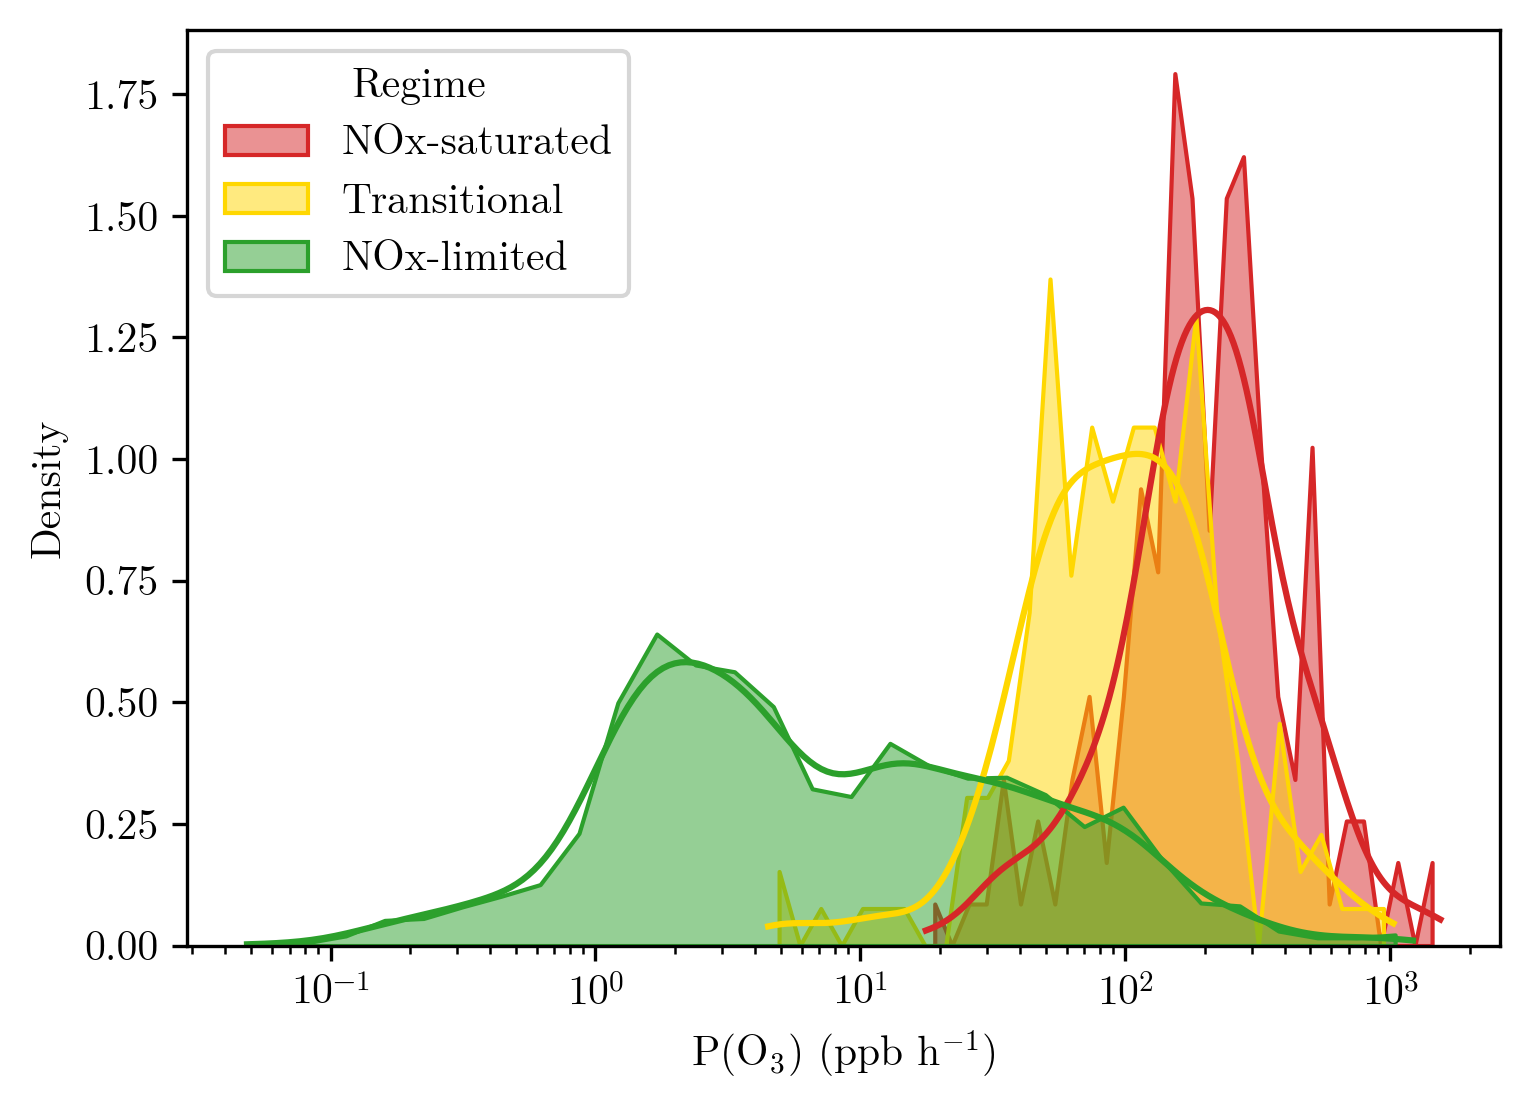

In [7]:
%matplotlib inline

import sys
from pathlib import Path

NB = Path("/home/jpalmo/fs09/Projects/TROPOMI_fire/paper/notebooks")
if str(NB) not in sys.path:
    sys.path.insert(0, str(NB))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from plume import AIRBORNE, ROOT, load_plume_table

import seaborn as sns

df = load_plume_table()
tmp = df[
    (df["pO3"] > 0)
    & (df["smoke_age"] > 10)
    & (df["oh_phenol_benzene"] > 0)
    & (df["CO"] > 500)
].copy()
order = ["nox_saturated", "transitional", "nox_limited"]
palette = {"nox_saturated": "tab:red", "transitional": "gold", "nox_limited": "tab:green"}
names = {"nox_saturated": "NOx-saturated", "transitional": "Transitional", "nox_limited": "NOx-limited"}

fig, ax = plt.subplots(figsize=(5.2, 3.8), dpi=300)
for regime in order:
    part = tmp.loc[tmp["regime"] == regime, "pO3"]
    print(f"{names[regime]}: n = {len(part)}, median P(O3) = {part.median():.1f} ppb h$^{{-1}}$")
    sns.histplot(
        part, bins=30, stat="density", element="poly", kde=True,
        common_norm=False, log_scale=True, color=palette[regime],
        alpha=0.5, ax=ax, label=names[regime],
    )
ax.set_xlabel(r"P(O$_3$) (ppb h$^{-1}$)")
ax.set_ylabel("Density")
ax.legend(frameon=True, title="Regime", loc="upper left")
fig.tight_layout()
png_path = "/home/jpalmo/fs09/Projects/TROPOMI_fire/paper/figs/pngs/figs08.png"
plt.savefig(png_path, dpi=300)
pdf_path = "/home/jpalmo/fs09/Projects/TROPOMI_fire/paper/figs/pdfs/figs08.pdf"
plt.savefig(pdf_path, dpi=300)
plt.show()
